In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [14]:
titanic = sns.load_dataset("titanic")

features = ["pclass","sex","fare","embarked","age"]
target = ["survived"]

# Missing Age values → median
imp_median = SimpleImputer(strategy="median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]])

# Missing Embarked values → most frequent
imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

X = titanic[features]
y = titanic[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state=42
)



In [24]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training accuracy:", accuracy_score(y_test, y_pred_test) * 100, "%")
print("Testing accuracy:", accuracy_score(y_train, y_pred_train) * 100, "%")


Training accuracy: 75.41899441340783 %
Testing accuracy: 97.75280898876404 %


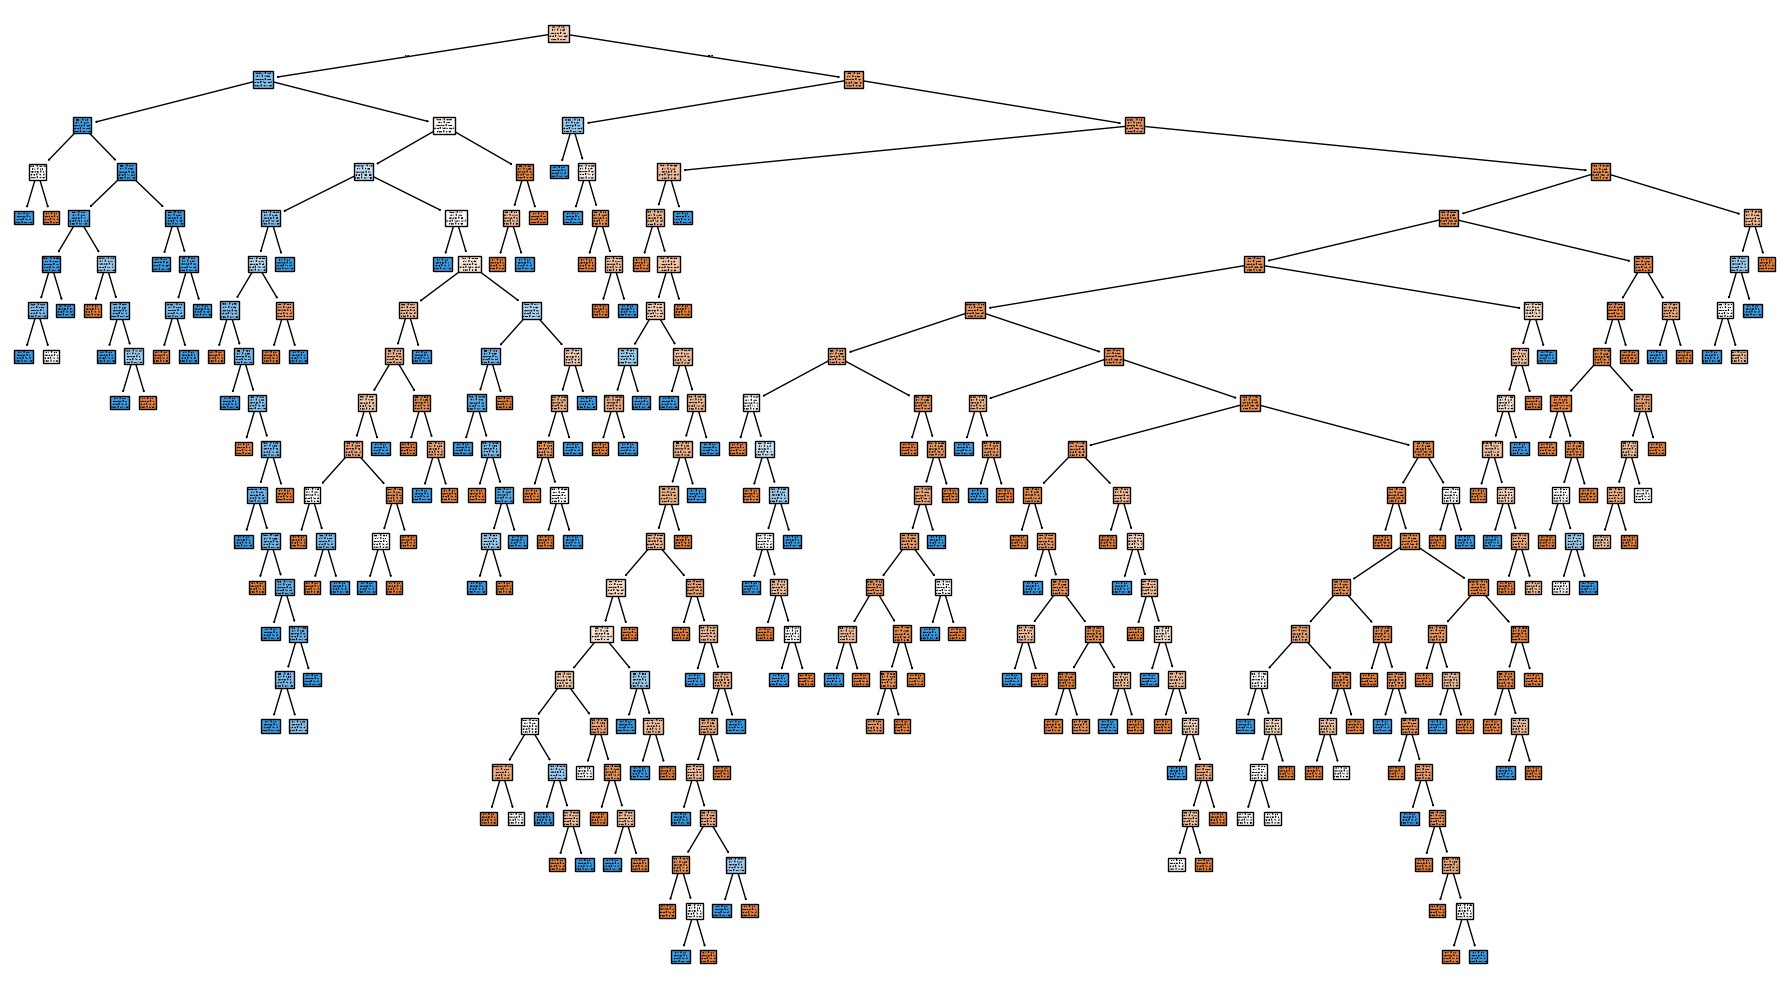

In [26]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died","Survived"],
    filled=True,
)
plt.tight_layout()
plt.show()

In [27]:
#Random forest 
from sklearn.ensemble import RandomForestClassifier

rf = RandomClassifier(
    